In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

df = pd.read_csv("data/clean/ab_clean.csv")
s = df.groupby("group")["converted"].agg(n="size", x="sum")
x_c, n_c = s.loc["control", "x"], s.loc["control", "n"]
x_t, n_t = s.loc["treatment", "x"], s.loc["treatment", "n"]

rng = np.random.default_rng(42)
draws = 200_000
post_c = rng.beta(1 + x_c, 1 + n_c - x_c, draws)
post_t = rng.beta(1 + x_t, 1 + n_t - x_t, draws)

In [2]:
diff = post_t - post_c
prob_t_better = (diff > 0).mean()
ci_low, ci_high = np.percentile(diff, [2.5, 97.5])
loss_if_ship = np.maximum(-diff, 0).mean()
loss_if_keep = np.maximum(diff, 0).mean()

print(f"Chance new page is better:     {prob_t_better*100:.1f}%")
print(f"95% credible interval:         {ci_low*100:+.3f} to {ci_high*100:+.3f} pp")
print(f"Expected loss if we SHIP new:  {loss_if_ship*10000:.1f} conversions per 10,000 users")
print(f"Expected loss if we KEEP old:  {loss_if_keep*10000:.1f} conversions per 10,000 users")

Chance new page is better:     9.5%
95% credible interval:         -0.393 to +0.080 pp
Expected loss if we SHIP new:  16.3 conversions per 10,000 users
Expected loss if we KEEP old:  0.5 conversions per 10,000 users


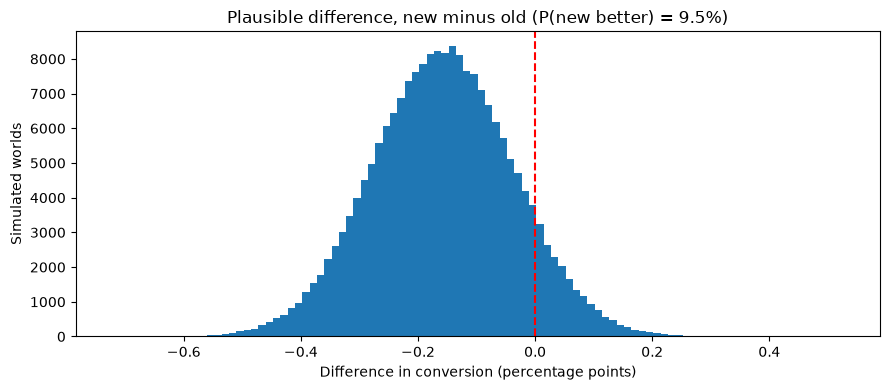

In [3]:
plt.figure(figsize=(9, 4))
plt.hist(diff * 100, bins=100)
plt.axvline(0, color="red", linestyle="--")
plt.title(f"Plausible difference, new minus old (P(new better) = {prob_t_better*100:.1f}%)")
plt.xlabel("Difference in conversion (percentage points)")
plt.ylabel("Simulated worlds")
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/bayes_difference.png", dpi=150)
plt.show()